# First pass of cleaning the gnomad frequencies from the genomes vat table

## Load libraries

In [1]:
library(readr)
library(data.table)
library(stringr)

## Load 3 different dataframes with gnomad information

Global and pop specific frequencies

In [2]:
dat1 <- read.csv("/grid/chambwe/home/founta/code_athon/results/global_freq_gnomad.tsv",sep="")
head(dat1)
dim(dat1)
length(unique(dat1$locus))

,locus,alleles,X__uid_5
,<chr>,<chr>,<chr>
1,chr1:19254,"[""G"",""A""]","[7.428071507568379E-5,2.6767414114839855E-4,0.0,0.0,0.0,0.0,0.0,0.0,2.5645409471704566E-4,0.0,0.0,0.0,4.779505480499618E-5,1.0275028256327705E-4,0.0,0.0,0.0,0.0,0.0,0.0,1.5906680805938495E-4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3.6959467783663914E-4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,null,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,null,0.0,0.0,0.0,0.0,0.0,0.0,null,0.0,0.0,0.0,0.0,null,0.0,0.0,null,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,null,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null]"
2,chr1:19254,"[""G"",""C""]","[0.02968304544692269,0.08304040836288054,0.018808386962839943,0.02011251758087201,0.014563106796116505,0.024324324324324326,0.030141843971631204,0.021739130434782608,0.054906151893661076,0.00743208610968734,0.014543339150668994,0.030131089806300138,0.029540047581284694,0.02983606557377049,0.018179225778855064,0.015675675675675675,0.0,0.023415977961432508,0.029197080291970802,0.01948051948051948,0.054780876494023904,0.007611241217798595,0.014672686230248307,0.031604184829991284,0.019685822231059854,0.02167300380228137,0.028846153846153848,0.025198938992042442,0.03103448275862069,0.024344569288389514,0.05505116010952587,0.007292616226071103,0.014498432601880877,0.02893148739794107,0.013860887096774193,0.03888633225954901,0.0,0.012658227848101266,0.03076923076923077,0.006097560975609756,0.0,0.0058823529411764705,0.0,0.006024096385542169,0.01948051948051948,0.0125,0.07317073170731707,0.01639344262295082,0.025974025974025976,0.021739130434782608,0.0,0.012195121951219513,0.04054054054054054,0.013157894736842105,0.011363636363636364,0.050724637681159424,0.007142857142857143,0.0,0.012345679012345678,0.0,0.0,0.01282051282051282,0.014242115971515769,0.013486513486513486,0.0,0.0,0.030303030303030304,0.0,0.0,0.013513513513513514,0.0,0.0,0.011363636363636364,0.0,0.08108108108108109,0.016666666666666666,0.038461538461538464,0.02564102564102564,0.0,0.0,0.045454545454545456,0.023809523809523808,0.011363636363636364,0.06578947368421052,0.0,0.0,0.015625,0.0,0.0,0.014285714285714285,0.0,0.023809523809523808,0.03125,0.011627906976744186,0.0,0.0,0.0,0.011111111111111112,0.030303030303030304,0.023255813953488372,0.06666666666666667,0.016129032258064516,0.013157894736842105,0.016666666666666666,0.0,0.021739130434782608,0.03333333333333333,0.0,0.011363636363636364,0.03225806451612903,0.013157894736842105,0.0,0.01020408163265306,0.0,0.0,0.011627906976744186,0.008384146341463415,0.02958152958152958,0.0,0.0,0.0,0.125,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0625,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.075,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0021551724137931034,0.01179245283018868,0.0,0.0,0.0,0.5,0.0,null,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,null,0.0,0.0,0.0,0.0,0.0,0.0,null,0.0,0.0,0.0,0.0,0.0,0.0,0.0,null,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.07142857142857142,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.07692307692307693,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.13636363636363635,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.05263157894736842,0.0,0.055555555

[1] 615363      3

[1] 335928

Gnomad pop group max frequency

In [3]:
dat2 <- read.csv("/grid/chambwe/home/founta/code_athon/results/grpmax_freq_gnomad.tsv",sep="")
head(dat2)
dim(dat2)
length(unique(dat2$locus))

,locus,alleles,X__uid_6
,<chr>,<chr>,<dbl>
1,chr1:19254,"[""G"",""A""]",0.00025645
2,chr1:19254,"[""G"",""C""]",0.05490600
3,chr1:20250,"[""T"",""C""]",0.35534000
4,chr1:48186,"[""T"",""G""]",0.09469500
5,chr1:81590,"[""AC"",""A""]",0.10468000
6,chr1:93726,"[""C"",""G""]",NA


[1] 615363      3

[1] 335928

Gnomad ancestry group with max frequency

In [4]:
dat3 <- read.csv("/grid/chambwe/home/founta/code_athon/results/grpmax_ancestry_gnomad.tsv",sep="")
head(dat3)
dim(dat3)
length(unique(dat3$locus))

,locus,alleles,X__uid_7
,<chr>,<chr>,<chr>
1,chr1:19254,"[""G"",""A""]",afr
2,chr1:19254,"[""G"",""C""]",afr
3,chr1:20250,"[""T"",""C""]",eas
4,chr1:48186,"[""T"",""G""]",sas
5,chr1:81590,"[""AC"",""A""]",sas
6,chr1:93726,"[""C"",""G""]",NA


[1] 615363      3

[1] 335928

## Combine different dataframes and clean data

In [5]:
merged1 <- merge(dat1,dat2,by=c("locus","alleles"))
merged2 <- merge(merged1,dat3,by=c("locus","alleles"))
head(merged2)

,locus,alleles,X__uid_5,X__uid_6,X__uid_7
,<chr>,<chr>,<chr>,<dbl>,<chr>
1,chr10:100014590,"[""G"",""A""]","[1.973216869688758E-5,1.9702362970065542E-5,0.0,0.0,0.0,0.0,0.0,0.0,2.4156923374239057E-5,0.0,0.0,1.3104442405975625E-4,2.5710906566565537E-5,1.3468376252558991E-5,0.0,0.0,0.0,0.0,0.0,0.0,4.518752824220515E-5,0.0,0.0,1.4749262536873156E-4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.178967224711153E-4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,null,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,null,0.0,0.0,0.0,0.0,0.0,0.0,null,0.0,0.0,0.0,0.0,0.0,0.0,0.0,null,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,null,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null]",1.3104e-04,amr
2,chr10:100014590,"[""G"",""C""]","[0.00958947326909679,0.009613996403774723,1.4707612660312978E-4,0.0,0.01020408163265306,0.006161137440758294,0.0,0.0,0.03336384659857391,0.0,2.0755500207555002E-4,0.00307551367622039,0.009719972228650776,0.009452990533562822,1.5254754398454185E-4,0.0,0.0,0.006666666666666667,0.0,0.0,0.032601824257202205,0.0,8.680555555555555E-4,0.0029472443265546712,1.3956734124214934E-4,0.0,0.02,0.005660377358490566,0.0,0.0,0.03423525766807808,0.0,0.0,0.0031779661016949155,0.01247987117552335,0.01247987117552335,0.0,0.0,0.01875,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.04782608695652174,0.0058823529411764705,0.0,0.03804347826086957,0.0,0.008064516129032258,0.049019607843137254,0.0,0.04310344827586207,0.0755813953488372,0.0,0.0,0.05339805825242718,0.0,0.0,0.0,0.011308562197092083,0.013643659711075442,0.0,0.0,0.0125,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.02586206896551724,0.0,0.0,0.031914893617021274,0.0,0.016666666666666666,0.03571428571428571,0.0,0.03508771929824561,0.08695652173913043,0.0,0.0,0.06382978723404255,0.0,0.0,0.0,0.0,0.0,0.025,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.07017543859649122,0.011904761904761904,0.0,0.044444444444444446,0.0,0.0,0.06521739130434782,0.0,0.05084745762711865,0.0625,0.0,0.0,0.044642857142857144,0.0,0.0,0.0,0.008782201405152224,0.008782201405152224,0.0,0.0,0.02631578947368421,0.1,0.0,0.0625,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.1,0.0,0.0,0.011904761904761904,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.09523809523809523,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.003401360544217687,0.011607142857142858,0.0,0.0,0.0,0.0,0.0,null,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.14285714285714285,0.0,0.0,0.0,0.0,null,0.0,0.0,0.0,0.0,0.0,0.0,null,0.0,0.0,0.0,0.0,0.0,0.0,0.0,null,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.07692307692307693,0.1111111111111111,0.0,0.0625,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.07692307692307693,0.0,0.0,0.02,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.18181818181818182,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.022727272727272728,0.0,0.0,0.0,0.0,0.0,null,0.022727272727272728,0.0,0.0,0.0,0.0,0.0,0.0,0.0,null,null,0.0]",3.3364e-02,afr
3,chr10:100038123,"[""G"",""A""]","[0.02099760027425437,0.021038107752956635,7.213944997349979E-4,0.0,0.017006802721088437,0.021780303030303032,0.0,0.0025921658986175116,0.06946930482318224,0.0,6.247396917950854E-4,0.013230647709320696,0.021339106231637546,0.020639848812095032,6.869529818847955E-4,0.0,0.0,0.020038167938931296,0.0,5.353319057815846E-4,0.06865414284417824,0.0,0.0017421602787

In [6]:
str_count(merged2[1,3], ',')

[1] 281

Create appropriate names for clean columns

In [7]:
colnames(merged2)[c(4:5)] <- c("grpmax_freq","grpmax_ancestry") 
colnames(merged2)

[1] "locus"           "alleles"         "X__uid_5"        "grpmax_freq"    
[5] "grpmax_ancestry"

In [8]:
head(merged2)

,locus,alleles,X__uid_5,grpmax_freq,grpmax_ancestry
,<chr>,<chr>,<chr>,<dbl>,<chr>
1,chr10:100014590,"[""G"",""A""]","[1.973216869688758E-5,1.9702362970065542E-5,0.0,0.0,0.0,0.0,0.0,0.0,2.4156923374239057E-5,0.0,0.0,1.3104442405975625E-4,2.5710906566565537E-5,1.3468376252558991E-5,0.0,0.0,0.0,0.0,0.0,0.0,4.518752824220515E-5,0.0,0.0,1.4749262536873156E-4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.178967224711153E-4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,null,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,null,0.0,0.0,0.0,0.0,0.0,0.0,null,0.0,0.0,0.0,0.0,0.0,0.0,0.0,null,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,null,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null]",1.3104e-04,amr
2,chr10:100014590,"[""G"",""C""]","[0.00958947326909679,0.009613996403774723,1.4707612660312978E-4,0.0,0.01020408163265306,0.006161137440758294,0.0,0.0,0.03336384659857391,0.0,2.0755500207555002E-4,0.00307551367622039,0.009719972228650776,0.009452990533562822,1.5254754398454185E-4,0.0,0.0,0.006666666666666667,0.0,0.0,0.032601824257202205,0.0,8.680555555555555E-4,0.0029472443265546712,1.3956734124214934E-4,0.0,0.02,0.005660377358490566,0.0,0.0,0.03423525766807808,0.0,0.0,0.0031779661016949155,0.01247987117552335,0.01247987117552335,0.0,0.0,0.01875,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.04782608695652174,0.0058823529411764705,0.0,0.03804347826086957,0.0,0.008064516129032258,0.049019607843137254,0.0,0.04310344827586207,0.0755813953488372,0.0,0.0,0.05339805825242718,0.0,0.0,0.0,0.011308562197092083,0.013643659711075442,0.0,0.0,0.0125,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.02586206896551724,0.0,0.0,0.031914893617021274,0.0,0.016666666666666666,0.03571428571428571,0.0,0.03508771929824561,0.08695652173913043,0.0,0.0,0.06382978723404255,0.0,0.0,0.0,0.0,0.0,0.025,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.07017543859649122,0.011904761904761904,0.0,0.044444444444444446,0.0,0.0,0.06521739130434782,0.0,0.05084745762711865,0.0625,0.0,0.0,0.044642857142857144,0.0,0.0,0.0,0.008782201405152224,0.008782201405152224,0.0,0.0,0.02631578947368421,0.1,0.0,0.0625,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.1,0.0,0.0,0.011904761904761904,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.09523809523809523,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.003401360544217687,0.011607142857142858,0.0,0.0,0.0,0.0,0.0,null,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.14285714285714285,0.0,0.0,0.0,0.0,null,0.0,0.0,0.0,0.0,0.0,0.0,null,0.0,0.0,0.0,0.0,0.0,0.0,0.0,null,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.07692307692307693,0.1111111111111111,0.0,0.0625,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.07692307692307693,0.0,0.0,0.02,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.18181818181818182,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.022727272727272728,0.0,0.0,0.0,0.0,0.0,null,0.022727272727272728,0.0,0.0,0.0,0.0,0.0,0.0,0.0,null,null,0.0]",3.3364e-02,afr
3,chr10:100038123,"[""G"",""A""]","[0.02099760027425437,0.021038107752956635,7.213944997349979E-4,0.0,0.017006802721088437,0.021780303030303032,0.0,0.0025921658986175116,0.06946930482318224,0.0,6.247396917950854E-4,0.013230647709320696,0.021339106231637546,0.020639848812095032,6.869529818847955E-4,0.0,0.0,0.020038167938931296,0.0,5.353319057815846E-4,0.06865414284417824,0.0,0.001

Keep 5000 entries

In [10]:
df <- merged2[grepl("chr1:", merged2$locus),]
head(df)

,locus,alleles,X__uid_5,grpmax_freq,grpmax_ancestry
,<chr>,<chr>,<chr>,<dbl>,<chr>
255245,chr1:100000723,"[""G"",""A""]","[0.15128481628573684,0.15139421309667594,0.10491465567981166,0.06526256139025312,0.14285714285714285,0.14265402843601896,0.1600877192982456,0.07463976945244957,0.29686520376175546,0.0214203010420687,0.08938199917046868,0.10382299031159989,0.15525936599423631,0.14713002313195975,0.10696302324398556,0.0734836702954899,0.125,0.13766730401529637,0.16595744680851063,0.07770632368703108,0.2920021713561929,0.017195767195767195,0.08695652173913043,0.1022995283018868,0.1021021021021021,0.062624750499002,0.16,0.1475563909774436,0.15384615384615385,0.07107231920199501,0.30241685602148316,0.024708304735758406,0.09014161220043573,0.10504003768252473,0.14472624798711756,0.14472624798711756,0.017045454545454544,0.1,0.31875,0.0673076923076923,0.09090909090909091,0.06372549019607843,0.14285714285714285,0.09223300970873786,0.09693877551020408,0.08854166666666667,0.3565217391304348,0.011764705882352941,0.18686868686868688,0.2826086956521739,0.014705882352941176,0.04838709677419355,0.2549019607843137,0.0797872340425532,0.4224137931034483,0.3488372093023256,0.10919540229885058,0.014705882352941176,0.3446601941747573,0.07352941176470588,0.01485148514851485,0.09693877551020408,0.13933764135702748,0.15008025682182985,0.010869565217391304,0.11956521739130435,0.275,0.09615384615384616,0.06862745098039216,0.08333333333333333,0.13559322033898305,0.07,0.09166666666666666,0.11956521739130435,0.3275862068965517,0.011627906976744186,0.14893617021276595,0.22340425531914893,0.00980392156862745,0.0,0.26785714285714285,0.0784313725490196,0.45614035087719296,0.3695652173913043,0.14285714285714285,0.008771929824561403,0.30851063829787234,0.06521739130434782,0.018518518518518517,0.09523809523809523,0.023809523809523808,0.08333333333333333,0.3625,0.038461538461538464,0.11458333333333333,0.05,0.15,0.11320754716981132,0.10526315789473684,0.06,0.38596491228070173,0.011904761904761904,0.22115384615384615,0.34444444444444444,0.0196078431372549,0.09375,0.2391304347826087,0.08139534883720931,0.3898305084745763,0.325,0.07777777777777778,0.022222222222222223,0.375,0.08035714285714286,0.010638297872340425,0.09821428571428571,0.12236533957845433,0.12236533957845433,0.11764705882352941,0.125,0.19736842105263158,0.25,0.1111111111111111,0.1875,0.18181818181818182,0.05,0.0625,0.18181818181818182,0.0,0.0,0.2,0.3,0.0,0.17857142857142858,0.21428571428571427,0.0,0.1956521739130435,0.0,0.0,0.0,0.05,0.0,0.1,0.08695652173913043,0.0,0.07407407407407407,0.38095238095238093,0.0,0.0,0.0,0.0625,0.125,0.0,0.07142857142857142,0.02,0.22727272727272727,0.0,0.1,0.0,0.08333333333333333,0.11363636363636363,0.07142857142857142,0.03571428571428571,0.0,0.09523809523809523,0.13660714285714284,0.15,0.125,0.2,0.5,0.125,null,0.2857142857142857,0.0,0.0,0.0,0.0,0.0,0.14285714285714285,0.21428571428571427,0.0,0.125,0.14705882352941177,0.0,null,0.0,0.0,0.0,0.16666666666666666,0.0,0.1111111111111111,null,0.0,0.08333333333333333,0.25,0.0,0.0,0.0,0.0,null,0.0,0.25,0.0,0.25,0.0,0.16666666666666666,0.0,0.0,0.0,0.08333333333333333,0.0,0.0,0.07142857142857142,0.125,0.19230769230769232,0.2222222222222222,0.09090909090909091,0.1875,0.13333333333333333,0.07142857142857142,0.1,0.2222222222222222,0.0,0.0,0.2222222222222222,0.34615384615384615,0.0,0.25,0.26,0.0,0.1956521739130435,0.0,0.0,0.0,0.0,0.0,0.09375,0.08695652173913043,0.0,0.06666666666666667,0.5,0.0,0.0,0.0,0.07894736842105263,0.125,0.0,0.029411764705882353,0.027777777777777776,0.21428571428571427,0.0,0.07142857142857142,0.0,0.125,0.1388888888888889,0.045454545454545456,0.05,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.45454545454545453,0.0,0.5,0.0,0.0,0.4166666666666667,null,0.45454545454545453,0.0,0.0,0.5,0.5,0.0,0.0,0.0,null,null,0.4166666666666667]",0.296870,afr
255246,chr1:100003060,"[""C"",""T""]","[0.05877941930985489,0.05890655567664089,0.045906656465187455,0.04041264433087261,0.023809523809523808,0.04962192816635161,0.04824561403508772,0.013840830449

In [12]:
df2 <- df[c(1:5000),]

### Load gnomad frequency globals and process data accordingly

In [13]:
globals <- read.csv("/grid/chambwe/home/founta/code_athon/metadata/global_freq_globals.tsv",sep="")
head(globals)

freq_meta                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                       

Create function to extract information of interest form the table

In [14]:
library(stringr)  
library(dplyr)

# Function to extract a specific index from the frequency string  
extract_freq <- function(freq_str, idx) {  
  # Remove brackets  
  cleaned <- gsub("^\\[|\\]$", "", freq_str)  
  # Split by comma  
  values <- strsplit(cleaned, ",")[[1]]  
  # Extract index (1-based in R)  
  val <- values[idx + 1]  # +1 because R is 1-indexed  
  # Convert to numeric (null -> NA)  
  ifelse(val == "null", NA_real_, as.numeric(val))  
}

# Vectorized version  
extract_freq_vec <- function(freq_str, idx) {  
  sapply(freq_str, extract_freq, idx = idx)  
}



Attaching package: ‘dplyr’


The following objects are masked from ‘package:data.table’:

    between, first, last


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union




Keep first all sequencies of interest from gnomad gobal frequency entry (raw and ajusted frequency for hgdp and 1kgp data)

In [15]:
proc <- df2

# First, parse the frequency array properly  
# The X__uid_5 column contains comma-separated values in brackets


# Now create columns for all groups of interest  
proc <- proc %>%  
  mutate(  
    # ── GLOBAL ──────────────────────────────────  
    freq_adj           = extract_freq_vec(X__uid_5, 0),  
    freq_raw           = extract_freq_vec(X__uid_5, 1),  
    freq_adj_XX        = extract_freq_vec(X__uid_5, 12),  
    freq_adj_XY        = extract_freq_vec(X__uid_5, 13),  
      
    # ── GLOBAL by ancestry ──────────────────────  
    freq_nfe           = extract_freq_vec(X__uid_5, 2),  
    freq_fin           = extract_freq_vec(X__uid_5, 3),  
    freq_mid           = extract_freq_vec(X__uid_5, 4),  
    freq_remaining     = extract_freq_vec(X__uid_5, 5),  
    freq_ami           = extract_freq_vec(X__uid_5, 6),  
    freq_asj           = extract_freq_vec(X__uid_5, 7),  
    freq_afr           = extract_freq_vec(X__uid_5, 8),  
    freq_eas           = extract_freq_vec(X__uid_5, 9),  
    freq_sas           = extract_freq_vec(X__uid_5, 10),  
    freq_amr           = extract_freq_vec(X__uid_5, 11),  
      
    # ── TGP overall ─────────────────────────────  
    freq_tgp_adj       = extract_freq_vec(X__uid_5, 34),  
    freq_tgp_raw       = extract_freq_vec(X__uid_5, 35),  
    freq_tgp_adj_XX    = extract_freq_vec(X__uid_5, 62),  
    freq_tgp_adj_XY    = extract_freq_vec(X__uid_5, 63),  
      
    # ── TGP by ancestry ─────────────────────────  
    freq_tgp_cdx       = extract_freq_vec(X__uid_5, 36),  
    freq_tgp_gih       = extract_freq_vec(X__uid_5, 37),  
    freq_tgp_msl       = extract_freq_vec(X__uid_5, 38),  
    freq_tgp_ibs       = extract_freq_vec(X__uid_5, 39),  
    freq_tgp_beb       = extract_freq_vec(X__uid_5, 40),  
    freq_tgp_itu       = extract_freq_vec(X__uid_5, 41),  
    freq_tgp_ceu       = extract_freq_vec(X__uid_5, 42),  
    freq_tgp_tsi       = extract_freq_vec(X__uid_5, 43),  
    freq_tgp_fin       = extract_freq_vec(X__uid_5, 44),  
    freq_tgp_pjl       = extract_freq_vec(X__uid_5, 45),  
    freq_tgp_gwd       = extract_freq_vec(X__uid_5, 46),  
    freq_tgp_pel       = extract_freq_vec(X__uid_5, 47),  
    freq_tgp_pur       = extract_freq_vec(X__uid_5, 48),  
    freq_tgp_acb       = extract_freq_vec(X__uid_5, 49),  
    freq_tgp_chs       = extract_freq_vec(X__uid_5, 50),  
    freq_tgp_mxl       = extract_freq_vec(X__uid_5, 51),  
    freq_tgp_asw       = extract_freq_vec(X__uid_5, 52),  
    freq_tgp_clm       = extract_freq_vec(X__uid_5, 53),  
    freq_tgp_yri       = extract_freq_vec(X__uid_5, 54),  
    freq_tgp_lwk       = extract_freq_vec(X__uid_5, 55),  
    freq_tgp_gbr       = extract_freq_vec(X__uid_5, 56),  
    freq_tgp_chb       = extract_freq_vec(X__uid_5, 57),  
    freq_tgp_esn       = extract_freq_vec(X__uid_5, 58),  
    freq_tgp_jpt       = extract_freq_vec(X__uid_5, 59),  
    freq_tgp_khv       = extract_freq_vec(X__uid_5, 60),  
    freq_tgp_stu       = extract_freq_vec(X__uid_5, 61),  
      
    # ── HGDP overall ────────────────────────────  
    freq_hgdp_adj      = extract_freq_vec(X__uid_5, 116),  
    freq_hgdp_raw      = extract_freq_vec(X__uid_5, 117),  
    freq_hgdp_adj_XX   = extract_freq_vec(X__uid_5, 164),  
    freq_hgdp_adj_XY   = extract_freq_vec(X__uid_5, 165),  
      
    # ── HGDP by ancestry ────────────────────────  
    freq_hgdp_adygei        = extract_freq_vec(X__uid_5, 118),  
    freq_hgdp_burusho       = extract_freq_vec(X__uid_5, 119),  
    freq_hgdp_palestinian   = extract_freq_vec(X__uid_5, 120),  
    freq_hgdp_bantukenya    = extract_freq_vec(X__uid_5, 121),  
    freq_hgdp_french        = extract_freq_vec(X__uid_5, 122),  
    freq_hgdp_bantusa       = extract_freq_vec(X__uid_5, 123),  
    freq_hgdp_basque        = extract_freq_vec(X__uid_5, 124),  
    freq_hgdp_tu            = extract_freq_vec(X__uid_5, 125),  
    freq_hgdp_dai           = extract_freq_vec(X__uid_5, 126),  
    freq_hgdp_makrani       = extract_freq_vec(X__uid_5, 127),  
    freq_hgdp_pima          = extract_freq_vec(X__uid_5, 128),  
    freq_hgdp_tujia         = extract_freq_vec(X__uid_5, 129),  
    freq_hgdp_mozabite      = extract_freq_vec(X__uid_5, 130),  
    freq_hgdp_mandenka      = extract_freq_vec(X__uid_5, 131),  
    freq_hgdp_surui         = extract_freq_vec(X__uid_5, 132),  
    freq_hgdp_orcadian      = extract_freq_vec(X__uid_5, 133),  
    freq_hgdp_bedouin       = extract_freq_vec(X__uid_5, 134),  
    freq_hgdp_she           = extract_freq_vec(X__uid_5, 135),  
    freq_hgdp_brahui        = extract_freq_vec(X__uid_5, 136),  
    freq_hgdp_naxi          = extract_freq_vec(X__uid_5, 137),  
    freq_hgdp_daur          = extract_freq_vec(X__uid_5, 138),  
    freq_hgdp_lahu          = extract_freq_vec(X__uid_5, 139),  
    freq_hgdp_miao          = extract_freq_vec(X__uid_5, 140),  
    freq_hgdp_xibo          = extract_freq_vec(X__uid_5, 141),  
    freq_hgdp_russian       = extract_freq_vec(X__uid_5, 142),  
    freq_hgdp_balochi       = extract_freq_vec(X__uid_5, 143),  
    freq_hgdp_maya          = extract_freq_vec(X__uid_5, 144),  
    freq_hgdp_sardinian     = extract_freq_vec(X__uid_5, 145),  
    freq_hgdp_yoruba        = extract_freq_vec(X__uid_5, 146),  
    freq_hgdp_colombian     = extract_freq_vec(X__uid_5, 147),  
    freq_hgdp_karitiana     = extract_freq_vec(X__uid_5, 148),  
    freq_hgdp_yi            = extract_freq_vec(X__uid_5, 149),  
    freq_hgdp_pathan        = extract_freq_vec(X__uid_5, 150),  
    freq_hgdp_hazara        = extract_freq_vec(X__uid_5, 151),  
    freq_hgdp_cambodian     = extract_freq_vec(X__uid_5, 152),  
    freq_hgdp_kalash        = extract_freq_vec(X__uid_5, 153),  
    freq_hgdp_yakut         = extract_freq_vec(X__uid_5, 154),  
    freq_hgdp_bergamo       = extract_freq_vec(X__uid_5, 155),  
    freq_hgdp_hezhen        = extract_freq_vec(X__uid_5, 156),  
    freq_hgdp_mongolian     = extract_freq_vec(X__uid_5, 157),  
    freq_hgdp_tuscan        = extract_freq_vec(X__uid_5, 158),  
    freq_hgdp_uygur         = extract_freq_vec(X__uid_5, 159),  
    freq_hgdp_sindhi        = extract_freq_vec(X__uid_5, 160),  
    freq_hgdp_druze         = extract_freq_vec(X__uid_5, 161),  
    freq_hgdp_japanese      = extract_freq_vec(X__uid_5, 162),  
    freq_hgdp_oroqen        = extract_freq_vec(X__uid_5, 163),  
    freq_hgdp_han           = extract_freq_vec(X__uid_5, 258),  
    freq_hgdp_northernhan   = extract_freq_vec(X__uid_5, 259),  
    freq_hgdp_biaka         = extract_freq_vec(X__uid_5, 264),  
    freq_hgdp_bougainville  = extract_freq_vec(X__uid_5, 265),  
    freq_hgdp_mbuti         = extract_freq_vec(X__uid_5, 266),  
    freq_hgdp_papuanh       = extract_freq_vec(X__uid_5, 267),  
    freq_hgdp_papuans       = extract_freq_vec(X__uid_5, 268),  
    freq_hgdp_san           = extract_freq_vec(X__uid_5, 269)  
  )  

In [16]:
head(proc)

,locus,alleles,X__uid_5,grpmax_freq,grpmax_ancestry,freq_adj,freq_raw,freq_adj_XX,freq_adj_XY,freq_nfe,⋯,freq_hgdp_japanese,freq_hgdp_oroqen,freq_hgdp_han,freq_hgdp_northernhan,freq_hgdp_biaka,freq_hgdp_bougainville,freq_hgdp_mbuti,freq_hgdp_papuanh,freq_hgdp_papuans,freq_hgdp_san
,<chr>,<chr>,<chr>,<dbl>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
255245,chr1:100000723,"[""G"",""A""]","[0.15128481628573684,0.15139421309667594,0.10491465567981166,0.06526256139025312,0.14285714285714285,0.14265402843601896,0.1600877192982456,0.07463976945244957,0.29686520376175546,0.0214203010420687,0.08938199917046868,0.10382299031159989,0.15525936599423631,0.14713002313195975,0.10696302324398556,0.0734836702954899,0.125,0.13766730401529637,0.16595744680851063,0.07770632368703108,0.2920021713561929,0.017195767195767195,0.08695652173913043,0.1022995283018868,0.1021021021021021,0.062624750499002,0.16,0.1475563909774436,0.15384615384615385,0.07107231920199501,0.30241685602148316,0.024708304735758406,0.09014161220043573,0.10504003768252473,0.14472624798711756,0.14472624798711756,0.017045454545454544,0.1,0.31875,0.0673076923076923,0.09090909090909091,0.06372549019607843,0.14285714285714285,0.09223300970873786,0.09693877551020408,0.08854166666666667,0.3565217391304348,0.011764705882352941,0.18686868686868688,0.2826086956521739,0.014705882352941176,0.04838709677419355,0.2549019607843137,0.0797872340425532,0.4224137931034483,0.3488372093023256,0.10919540229885058,0.014705882352941176,0.3446601941747573,0.07352941176470588,0.01485148514851485,0.09693877551020408,0.13933764135702748,0.15008025682182985,0.010869565217391304,0.11956521739130435,0.275,0.09615384615384616,0.06862745098039216,0.08333333333333333,0.13559322033898305,0.07,0.09166666666666666,0.11956521739130435,0.3275862068965517,0.011627906976744186,0.14893617021276595,0.22340425531914893,0.00980392156862745,0.0,0.26785714285714285,0.0784313725490196,0.45614035087719296,0.3695652173913043,0.14285714285714285,0.008771929824561403,0.30851063829787234,0.06521739130434782,0.018518518518518517,0.09523809523809523,0.023809523809523808,0.08333333333333333,0.3625,0.038461538461538464,0.11458333333333333,0.05,0.15,0.11320754716981132,0.10526315789473684,0.06,0.38596491228070173,0.011904761904761904,0.22115384615384615,0.34444444444444444,0.0196078431372549,0.09375,0.2391304347826087,0.08139534883720931,0.3898305084745763,0.325,0.07777777777777778,0.022222222222222223,0.375,0.08035714285714286,0.010638297872340425,0.09821428571428571,0.12236533957845433,0.12236533957845433,0.11764705882352941,0.125,0.19736842105263158,0.25,0.1111111111111111,0.1875,0.18181818181818182,0.05,0.0625,0.18181818181818182,0.0,0.0,0.2,0.3,0.0,0.17857142857142858,0.21428571428571427,0.0,0.1956521739130435,0.0,0.0,0.0,0.05,0.0,0.1,0.08695652173913043,0.0,0.07407407407407407,0.38095238095238093,0.0,0.0,0.0,0.0625,0.125,0.0,0.07142857142857142,0.02,0.22727272727272727,0.0,0.1,0.0,0.08333333333333333,0.11363636363636363,0.07142857142857142,0.03571428571428571,0.0,0.09523809523809523,0.13660714285714284,0.15,0.125,0.2,0.5,0.125,null,0.2857142857142857,0.0,0.0,0.0,0.0,0.0,0.14285714285714285,0.21428571428571427,0.0,0.125,0.14705882352941177,0.0,null,0.0,0.0,0.0,0.16666666666666666,0.0,0.1111111111111111,null,0.0,0.08333333333333333,0.25,0.0,0.0,0.0,0.0,null,0.0,0.25,0.0,0.25,0.0,0.16666666666666666,0.0,0.0,0.0,0.08333333333333333,0.0,0.0,0.07142857142857142,0.125,0.19230769230769232,0.2222222222222222,0.09090909090909091,0.1875,0.13333333333333333,0.07142857142857142,0.1,0.2222222222222222,0.0,0.0,0.2222222222222222,0.34615384615384615,0.0,0.25,0.26,0.0,0.1956521739130435,0.0,0.0,0.0,0.0,0.0,0.09375,0.08695652173913043,0.0,0.06666666666666667,0.5,0.0,0.0,0.0,0.07894736842105263,0.125,0.0,0.029411764705882353,0.027777777777777776,0.21428571428571427,0.0,0.07142857142857142,0.0,0.125,0.1388888888888889,0.045454545454545456,0.05,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.45454545454545453,0.0,0.

Sanity check -- Isolate last 13 indices

## Save results

In [18]:
write.csv(proc[,-3],"/grid/chambwe/home/founta/code_athon/results/gnomad_snps_processed.csv",row.names=F)

Load variants annotations

In [19]:
ann <- read.csv("~/code_athon/results/variant_annotations.csv")
head(ann)

,locus,alleles,present_in
,<chr>,<chr>,<chr>
1,chr1:169833619,"[""G"",""T""]",mage
2,chr6:143416357,"[""T"",""TA""]",mage
3,chr6:143418884,"[""T"",""A""]",mage
4,chr6:143422225,"[""A"",""G""]",mage
5,chr6:143425557,"[""A"",""G""]",mage
6,chr6:143431724,"[""T"",""G""]",mage


add annotations

In [20]:
final <- merge(proc[,-3], ann, by = c("locus", "alleles"), a)
dim(final)
head(final)

[1] 3036  107

,locus,alleles,grpmax_freq,grpmax_ancestry,freq_adj,freq_raw,freq_adj_XX,freq_adj_XY,freq_nfe,freq_fin,⋯,freq_hgdp_oroqen,freq_hgdp_han,freq_hgdp_northernhan,freq_hgdp_biaka,freq_hgdp_bougainville,freq_hgdp_mbuti,freq_hgdp_papuanh,freq_hgdp_papuans,freq_hgdp_san,present_in
,<chr>,<chr>,<dbl>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
1,chr1:100000723,"[""G"",""A""]",0.296870,afr,0.15128482,0.15139421,0.15525937,0.14713002,0.10491466,0.06526256,⋯,0.0,0.00000000,0.0000000,0.45454545,0.0000000,0.50000000,0.0,0.0,0.41666667,gtex
2,chr1:100003060,"[""C"",""T""]",0.104270,afr,0.05877942,0.05890656,0.05940428,0.05812640,0.04590666,0.04041264,⋯,0.0,0.00000000,0.0000000,0.04545455,0.0000000,0.04166667,0.0,0.0,0.08333333,gtex
3,chr1:10000458,"[""T"",""C""]",0.847600,nfe,0.65192073,0.65064836,0.65439633,0.64932471,0.84760375,0.78072014,⋯,0.5,0.43750000,0.6666667,0.11363636,0.1818182,0.00000000,0.5,0.5,0.00000000,gtex
4,chr1:100004946,"[""G"",""A""]",0.066957,afr,0.04822874,0.04831908,0.04831640,0.04813706,0.04582941,0.04046353,⋯,0.0,0.00000000,0.0000000,0.02272727,0.0000000,0.04166667,0.0,0.0,0.08333333,gtex
5,chr1:100006010,"[""T"",""C""]",0.296420,afr,0.15123875,0.15155731,0.15524779,0.14704855,0.10529024,0.06517638,⋯,0.0,0.00000000,0.0000000,0.45454545,0.0000000,0.50000000,0.0,0.0,0.50000000,gtex
6,chr1:100007048,"[""A"",""G""]",0.434300,afr,0.22021525,0.22046665,0.22564300,0.21454482,0.15058222,0.11394077,⋯,0.0,0.04545455,0.0500000,0.65909091,0.0000000,0.58333333,0.0,0.0,0.66666667,gtex


In [22]:
dim(unique(final[,c(1,2)]))

[1] 2758    2

In [23]:
final_dedup <- final[!duplicated(final[, c("locus", "alleles")]), ]  
dim(final_dedup)  

[1] 2758  107

In [24]:
table(final_dedup$present_in)


both gtex mage 
 214  962 1582 

In [49]:
dim(final_dedup)

[1] 2758  107

Data Processing

In [50]:
final <- final_dedup[,c(1,2,grep("hgdp", colnames(final_dedup)), grep("tgp", colnames(final_dedup)),grep("present", colnames(final_dedup)))]
head(final)

,locus,alleles,freq_hgdp_adj,freq_hgdp_raw,freq_hgdp_adj_XX,freq_hgdp_adj_XY,freq_hgdp_adygei,freq_hgdp_burusho,freq_hgdp_palestinian,freq_hgdp_bantukenya,⋯,freq_tgp_clm,freq_tgp_yri,freq_tgp_lwk,freq_tgp_gbr,freq_tgp_chb,freq_tgp_esn,freq_tgp_jpt,freq_tgp_khv,freq_tgp_stu,present_in
,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
1,chr1:100000723,"[""G"",""A""]",0.12236534,0.12236534,0.09523810,0.13660714,0.11764706,0.12500000,0.19736842,0.2500000,⋯,0.07978723,0.42241379,0.34883721,0.10919540,0.014705882,0.34466019,0.07352941,0.01485149,0.09693878,gtex
2,chr1:100003060,"[""C"",""T""]",0.02748538,0.02748538,0.02551020,0.02852050,0.02941176,0.02083333,0.05263158,0.1000000,⋯,0.03723404,0.13362069,0.13372093,0.05172414,0.009803922,0.12621359,0.07352941,0.00000000,0.07142857,gtex
3,chr1:10000458,"[""T"",""C""]",0.62945368,0.62989324,0.67413793,0.60597826,0.75000000,0.66666667,0.77631579,0.1111111,⋯,0.66489362,0.12500000,0.06976744,0.83333333,0.593137255,0.13592233,0.68137255,0.63500000,0.58163265,gtex
4,chr1:100004946,"[""G"",""A""]",0.02665877,0.02665877,0.02397260,0.02807971,0.02941176,0.02083333,0.05405405,0.0500000,⋯,0.03191489,0.06896552,0.08720930,0.05172414,0.009803922,0.08823529,0.07352941,0.00000000,0.07142857,gtex
5,chr1:100006010,"[""T"",""C""]",0.12339181,0.12339181,0.09693878,0.13725490,0.11764706,0.12500000,0.19736842,0.2500000,⋯,0.07978723,0.42672414,0.34883721,0.10919540,0.014705882,0.34466019,0.07352941,0.01485149,0.09693878,gtex
6,chr1:100007048,"[""A"",""G""]",0.17388759,0.17388759,0.13775510,0.19285714,0.20588235,0.12500000,0.27631579,0.3500000,⋯,0.10638298,0.56034483,0.42352941,0.18390805,0.073529412,0.54854369,0.08333333,0.06435644,0.13265306,gtex


In [57]:
library(tidyr)  
library(dplyr)

final3 <- final[-1,] %>%  
  pivot_longer(  
    cols = -c(locus, alleles, present_in),        # pivot all columns except locus and alleles  
    names_to = "population",          # column names go to "population"  
    values_to = "frequency"           # values go to "frequency"  
  ) %>%  
  select(locus, alleles, frequency, population, present_in)  # reorder columns

head(final3)

locus,alleles,frequency,population,present_in
<chr>,<chr>,<dbl>,<chr>,<chr>
chr1:100003060,"[""C"",""T""]",0.02748538,freq_hgdp_adj,gtex
chr1:100003060,"[""C"",""T""]",0.02748538,freq_hgdp_raw,gtex
chr1:100003060,"[""C"",""T""]",0.02551020,freq_hgdp_adj_XX,gtex
chr1:100003060,"[""C"",""T""]",0.02852050,freq_hgdp_adj_XY,gtex
chr1:100003060,"[""C"",""T""]",0.02941176,freq_hgdp_adygei,gtex
chr1:100003060,"[""C"",""T""]",0.02083333,freq_hgdp_burusho,gtex


In [58]:
final3 <- final3 %>%  
  mutate(set = ifelse(grepl("hgdp", population, ignore.case = TRUE), "HGDP", "TGP"))

final3$population <- gsub("freq_","", final3$population)

head(final3)

locus,alleles,frequency,population,present_in,set
<chr>,<chr>,<dbl>,<chr>,<chr>,<chr>
chr1:100003060,"[""C"",""T""]",0.02748538,hgdp_adj,gtex,HGDP
chr1:100003060,"[""C"",""T""]",0.02748538,hgdp_raw,gtex,HGDP
chr1:100003060,"[""C"",""T""]",0.02551020,hgdp_adj_XX,gtex,HGDP
chr1:100003060,"[""C"",""T""]",0.02852050,hgdp_adj_XY,gtex,HGDP
chr1:100003060,"[""C"",""T""]",0.02941176,hgdp_adygei,gtex,HGDP
chr1:100003060,"[""C"",""T""]",0.02083333,hgdp_burusho,gtex,HGDP


In [59]:
dim(final3)
final3$population

[1] 242616      6

[1] "hgdp_adj"          "hgdp_raw"          "hgdp_adj_XX"      
    [4] "hgdp_adj_XY"       "hgdp_adygei"       "hgdp_burusho"     
    [7] "hgdp_palestinian"  "hgdp_bantukenya"   "hgdp_french"      
   [10] "hgdp_bantusa"      "hgdp_basque"       "hgdp_tu"          
   [13] "hgdp_dai"          "hgdp_makrani"      "hgdp_pima"        
   [16] "hgdp_tujia"        "hgdp_mozabite"     "hgdp_mandenka"    
   [19] "hgdp_surui"        "hgdp_orcadian"     "hgdp_bedouin"     
   [22] "hgdp_she"          "hgdp_brahui"       "hgdp_naxi"        
   [25] "hgdp_daur"         "hgdp_lahu"         "hgdp_miao"        
   [28] "hgdp_xibo"         "hgdp_russian"      "hgdp_balochi"     
   [31] "hgdp_maya"         "hgdp_sardinian"    "hgdp_yoruba"      
   [34] "hgdp_colombian"    "hgdp_karitiana"    "hgdp_yi"          
   [37] "hgdp_pathan"       "hgdp_hazara"       "hgdp_cambodian"   
   [40] "hgdp_kalash"       "hgdp_yakut"        "hgdp_bergamo"     
   [43] "hgdp_hezhen"       "hgdp_mongolian"    "hgdp_tuscan"      
   [46] "hgdp_uygur"        "hgdp_sindhi"       "hgdp_druze"       
   [49] "hgdp_japanese"     "hgdp_oroqen"       "hgdp_han"         
   [52] "hgdp_northernhan"  "hgdp_biaka"        "hgdp_bougainville"
   [55] "hgdp_mbuti"        "hgdp_papuanh"      "hgdp_papuans"     
   [58] "hgdp_san"          "tgp_adj"           "tgp_raw"          
   [61] "tgp_adj_XX"        "tgp_adj_XY"        "tgp_cdx"          
   [64] "tgp_gih"           "tgp_msl"           "tgp_ibs"          
   [67] "tgp_beb"           "tgp_itu"           "tgp_ceu"          
   [70] "tgp_tsi"           "tgp_fin"           "tgp_pjl"          
   [73] "tgp_gwd"           "tgp_pel"           "tgp_pur"          
   [76] "tgp_acb"           "tgp_chs"           "tgp_mxl"          
   [79] "tgp_asw"           "tgp_clm"           "tgp_yri"          
   [82] "tgp_lwk"           "tgp_gbr"           "tgp_chb"          
   [85] "tgp_esn"           "tgp_jpt"           "tgp_khv"          
   [88] "tgp_stu"           "hgdp_adj"          "hgdp_raw"         
   [91] "hgdp_adj_XX"       "hgdp_adj_XY"       "hgdp_adygei"      
   [94] "hgdp_burusho"      "hgdp_palestinian"  "hgdp_bantukenya"  
   [97] "hgdp_french"       "hgdp_bantusa"      "hgdp_basque"      
  [100] "hgdp_tu"           "hgdp_dai"          "hgdp_makrani"     
  [103] "hgdp_pima"         "hgdp_tujia"        "hgdp_mozabite"    
  [106] "hgdp_mandenka"     "hgdp_surui"        "hgdp_orcadian"    
  [109] "hgdp_bedouin"      "hgdp_she"          "hgdp_brahui"      
  [112] "hgdp_naxi"         "hgdp_daur"         "hgdp_lahu"        
  [115] "hgdp_miao"         "hgdp_xibo"         "hgdp_russian"     
  [118] "hgdp_balochi"      "hgdp_maya"         "hgdp_sardinian"   
  [121] "hgdp_yoruba"       "hgdp_colombian"    "hgdp_karitiana"   
  [124] "hgdp_yi"           "hgdp_pathan"       "hgdp_hazara"      
  [127] "hgdp_cambodian"    "hgdp_kalash"       "hgdp_yakut"       
  [130] "hgdp_bergamo"      "hgdp_hezhen"       "hgdp_mongolian"   
  [133] "hgdp_tuscan"       "hgdp_uygur"        "hgdp_sindhi"      
  [136] "hgdp_druze"        "hgdp_japanese"     "hgdp_oroqen"      
  [139] "hgdp_han"          "hgdp_northernhan"  "hgdp_biaka"       
  [142] "hgdp_bougainville" "hgdp_mbuti"        "hgdp_papuanh"     
  [145] "hgdp_papuans"      "hgdp_san"          "tgp_adj"          
  [148] "tgp_raw"           "tgp_adj_XX"        "tgp_adj_XY"       
  [151] "tgp_cdx"           "tgp_gih"           "tgp_msl"          
  [154] "tgp_ibs"           "tgp_beb"           "tgp_itu"          
  [157] "tgp_ceu"           "tgp_tsi"           "tgp_fin"          
  [160] "tgp_pjl"           "tgp_gwd"           "tgp_pel"          
  [163] "tgp_pur"           "tgp_acb"           "tgp_chs"          
  [166] "tgp_mxl"           "tgp_asw"           "tgp_clm"          
  [169] "tgp_yri"           "tgp_lwk"           "tgp_gbr"          
  [172] "tgp_chb"           "tgp_esn"           "tgp_jpt"          
  [175] "tgp_khv"           "tgp_stu"           "hgdp_adj"  

In [60]:
final3$population <- sub("^[^_]*_", "", final3$population)
head(final3)

locus,alleles,frequency,population,present_in,set
<chr>,<chr>,<dbl>,<chr>,<chr>,<chr>
chr1:100003060,"[""C"",""T""]",0.02748538,adj,gtex,HGDP
chr1:100003060,"[""C"",""T""]",0.02748538,raw,gtex,HGDP
chr1:100003060,"[""C"",""T""]",0.02551020,adj_XX,gtex,HGDP
chr1:100003060,"[""C"",""T""]",0.02852050,adj_XY,gtex,HGDP
chr1:100003060,"[""C"",""T""]",0.02941176,adygei,gtex,HGDP
chr1:100003060,"[""C"",""T""]",0.02083333,burusho,gtex,HGDP


In [61]:
rows_to_remove <- union(grep("adj", final3$population), grep("raw", final3$population))  
to_plot <- final3[-rows_to_remove, ]
dim(to_plot)

[1] 220560      6

In [62]:
hgdp_ann <- read_delim("/grid/chambwe/home/founta/code_athon/metadata/igsr_hgdp.tsv", 
     delim = "\t", escape_double = FALSE, 
     trim_ws = TRUE)
head(hgdp_ann)


── Column specification ────────────────────────────────────────────────────────
cols(
  `Population code` = col_logical(),
  `Population elastic ID` = col_character(),
  `Population name` = col_character(),
  `Population description` = col_character(),
  `Population latitude` = col_double(),
  `Population longitude` = col_double(),
  `Superpopulation code` = col_logical(),
  `Superpopulation name` = col_character(),
  `Superpopulation display colour` = col_character(),
  `Superpopulation display order` = col_double(),
  `Data collections` = col_character()
)




Population code,Population elastic ID,Population name,Population description,Population latitude,Population longitude,Superpopulation code,Superpopulation name,Superpopulation display colour,Superpopulation display order,Data collections
<lgl>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<lgl>,<chr>,<chr>,<dbl>,<chr>
NA,AdygeiHGDP,Adygei,"Adygei in Caucasus, Russia (HGDP)",44.0,39.00,NA,Europe (HGDP),#3A85D4,10,Human Genome Diversity Project
NA,BalochiHGDP,Balochi,Balochi in Pakistan (HGDP),30.5,66.50,NA,Central South Asia (HGDP),#7B1FA2,8,Human Genome Diversity Project
NA,BantuKenyaHGDP,Bantu Kenya,Bantu in Kenya (HGDP),-3.0,37.00,NA,Africa (HGDP),#E8AE3C,6,Human Genome Diversity Project
NA,BantuSouthAfricaHGDP,Bantu South Africa,Bantu in South Africa (HGDP),-25.6,24.25,NA,Africa (HGDP),#E8AE3C,6,Human Genome Diversity Project
NA,BasqueHGDP,Basque,Basque in France (HGDP),43.0,0.00,NA,Europe (HGDP),#3A85D4,10,Human Genome Diversity Project
NA,BedouinHGDP,Bedouin,"Bedouin in Negev, Israel (HGDP)",31.0,35.00,NA,Middle East (HGDP),#7B3A10,11,Human Genome Diversity Project


In [63]:
hgdp_ann$`Population elastic ID` <- gsub("HGDP","", hgdp_ann$`Population elastic ID`)
hgdp_ann$`Population elastic ID` <- tolower(hgdp_ann$`Population elastic ID`)

hgdp_ann$`Population elastic ID`

[1] "adygei"           "balochi"          "bantukenya"       "bantusouthafrica"
 [5] "basque"           "bedouin"          "bergamoitalian"   "biaka"           
 [9] "bougainville"     "brahui"           "burusho"          "cambodian"       
[13] "colombian"        "dai"              "daur"             "druze"           
[17] "french"           "han"              "hazara"           "hezhen"          
[21] "japanese"         "kalash"           "karitiana"        "lahu"            
[25] "makrani"          "mandenka"         "maya"             "mbuti"           
[29] "miao"             "mongolian"        "mozabite"         "naxi"            
[33] "northernhan"      "orcadian"         "oroqen"           "palestinian"     
[37] "papuanhighlands"  "papuansepik"      "pathan"           "pima"            
[41] "russian"          "san"              "sardinian"        "she"             
[45] "sindhi"           "surui"            "tu"               "tujia"           
[49] "tuscan"           "uygur"            "xibo"             "yakut"           
[53] "yi"               "yoruba"

In [64]:
colnames(hgdp_ann)[c(2,8)] <- c("Population code","Superpopulation code")
head(hgdp_ann)

Population code,Population code,Population name,Population description,Population latitude,Population longitude,Superpopulation code,Superpopulation code,Superpopulation display colour,Superpopulation display order,Data collections
<lgl>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<lgl>,<chr>,<chr>,<dbl>,<chr>
NA,adygei,Adygei,"Adygei in Caucasus, Russia (HGDP)",44.0,39.00,NA,Europe (HGDP),#3A85D4,10,Human Genome Diversity Project
NA,balochi,Balochi,Balochi in Pakistan (HGDP),30.5,66.50,NA,Central South Asia (HGDP),#7B1FA2,8,Human Genome Diversity Project
NA,bantukenya,Bantu Kenya,Bantu in Kenya (HGDP),-3.0,37.00,NA,Africa (HGDP),#E8AE3C,6,Human Genome Diversity Project
NA,bantusouthafrica,Bantu South Africa,Bantu in South Africa (HGDP),-25.6,24.25,NA,Africa (HGDP),#E8AE3C,6,Human Genome Diversity Project
NA,basque,Basque,Basque in France (HGDP),43.0,0.00,NA,Europe (HGDP),#3A85D4,10,Human Genome Diversity Project
NA,bedouin,Bedouin,"Bedouin in Negev, Israel (HGDP)",31.0,35.00,NA,Middle East (HGDP),#7B3A10,11,Human Genome Diversity Project


In [65]:
kgp_ann <- read_delim("/grid/chambwe/home/founta/code_athon/metadata/igsr_1kgp_samples.tsv", 
     delim = "\t", escape_double = FALSE, 
     trim_ws = TRUE)

head(kgp_ann)


── Column specification ────────────────────────────────────────────────────────
cols(
  `Sample name` = col_character(),
  Sex = col_character(),
  `Biosample ID` = col_character(),
  `Population code` = col_character(),
  `Population name` = col_character(),
  `Superpopulation code` = col_character(),
  `Superpopulation name` = col_character(),
  `Population elastic ID` = col_character(),
  `Data collections` = col_character()
)




Sample name,Sex,Biosample ID,Population code,Population name,Superpopulation code,Superpopulation name,Population elastic ID,Data collections
<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
HG00096,M,SAME123268,GBR,British,EUR,European Ancestry,GBR,"1000 Genomes on GRCh38,1000 Genomes 30x on GRCh38,Human Genome Structural Variation Consortium, Phase 2,Human Genome Structural Variation Consortium, Phase 3,1KG_ONT_VIENNA,MAGE RNA-seq,1000 Genomes phase 3 release,1000 Genomes phase 1 release,Geuvadis"
HG00097,F,SAME123267,GBR,British,EUR,European Ancestry,GBR,"1000 Genomes on GRCh38,1000 Genomes 30x on GRCh38,Human Pangenome Reference Consortium, Phase 2,1000 Genomes phase 3 release,1000 Genomes phase 1 release,Geuvadis"
HG00098,M,SAME123272,GBR,British,EUR,European Ancestry,GBR,"1000 Genomes on GRCh38,1KG_ONT_VIENNA,Long-read direct RNA sequencing (ONT) of 60 EUR,1000 Genomes phase 3 release"
HG00099,F,SAME123271,GBR,British,EUR,European Ancestry,GBR,"1000 Genomes on GRCh38,1000 Genomes 30x on GRCh38,1KG_ONT_VIENNA,Human Pangenome Reference Consortium, Phase 2,Long-read direct RNA sequencing (ONT) of 60 EUR,1000 Genomes phase 3 release,1000 Genomes phase 1 release,Geuvadis"
HG00100,F,SAME125154,GBR,British,EUR,European Ancestry,GBR,"1000 Genomes on GRCh38,1000 Genomes 30x on GRCh38,1KG_ONT_VIENNA,MAGE RNA-seq,Long-read direct RNA sequencing (ONT) of 60 EUR,1000 Genomes phase 3 release,1000 Genomes phase 1 release,Geuvadis"
HG00101,M,SAME125153,GBR,British,EUR,European Ancestry,GBR,"1000 Genomes on GRCh38,1000 Genomes 30x on GRCh38,1KG_ONT_VIENNA,Long-read direct RNA sequencing (ONT) of 60 EUR,1000 Genomes phase 3 release,1000 Genomes phase 1 release,Geuvadis"


In [66]:
kgp_ann$`Population code` <- tolower(kgp_ann$`Population code`)
unique(kgp_ann$`Population code`)

[1] "gbr"     "fin"     "chs"     "pur"     "cdx"     "clm"     "ibs"    
 [8] "pel"     "pjl"     "khv"     "ibs,msl" "acb"     "gwd"     "esn"    
[15] "beb"     "msl"     "stu"     "itu"     "ceu"     "yri"     "chb"    
[22] "jpt"     "lwk"     "asw"     "mxl"     "tsi"     "gih"     "gwj"    
[29] "gwf"     "gww"     NA        "mkk"

In [67]:
to_plot$population[which(to_plot$set == "TGP")]

[1] "cdx" "gih" "msl" "ibs" "beb" "itu" "ceu" "tsi" "fin" "pjl" "gwd" "pel"
   [13] "pur" "acb" "chs" "mxl" "asw" "clm" "yri" "lwk" "gbr" "chb" "esn" "jpt"
   [25] "khv" "stu" "cdx" "gih" "msl" "ibs" "beb" "itu" "ceu" "tsi" "fin" "pjl"
   [37] "gwd" "pel" "pur" "acb" "chs" "mxl" "asw" "clm" "yri" "lwk" "gbr" "chb"
   [49] "esn" "jpt" "khv" "stu" "cdx" "gih" "msl" "ibs" "beb" "itu" "ceu" "tsi"
   [61] "fin" "pjl" "gwd" "pel" "pur" "acb" "chs" "mxl" "asw" "clm" "yri" "lwk"
   [73] "gbr" "chb" "esn" "jpt" "khv" "stu" "cdx" "gih" "msl" "ibs" "beb" "itu"
   [85] "ceu" "tsi" "fin" "pjl" "gwd" "pel" "pur" "acb" "chs" "mxl" "asw" "clm"
   [97] "yri" "lwk" "gbr" "chb" "esn" "jpt" "khv" "stu" "cdx" "gih" "msl" "ibs"
  [109] "beb" "itu" "ceu" "tsi" "fin" "pjl" "gwd" "pel" "pur" "acb" "chs" "mxl"
  [121] "asw" "clm" "yri" "lwk" "gbr" "chb" "esn" "jpt" "khv" "stu" "cdx" "gih"
  [133] "msl" "ibs" "beb" "itu" "ceu" "tsi" "fin" "pjl" "gwd" "pel" "pur" "acb"
  [145] "chs" "mxl" "asw" "clm" "yri" "lwk" "gbr" "chb" "esn" "jpt" "khv" "stu"
  [157] "cdx" "gih" "msl" "ibs" "beb" "itu" "ceu" "tsi" "fin" "pjl" "gwd" "pel"
  [169] "pur" "acb" "chs" "mxl" "asw" "clm" "yri" "lwk" "gbr" "chb" "esn" "jpt"
  [181] "khv" "stu" "cdx" "gih" "msl" "ibs" "beb" "itu" "ceu" "tsi" "fin" "pjl"
  [193] "gwd" "pel" "pur" "acb" "chs" "mxl" "asw" "clm" "yri" "lwk" "gbr" "chb"
  [205] "esn" "jpt" "khv" "stu" "cdx" "gih" "msl" "ibs" "beb" "itu" "ceu" "tsi"
  [217] "fin" "pjl" "gwd" "pel" "pur" "acb" "chs" "mxl" "asw" "clm" "yri" "lwk"
  [229] "gbr" "chb" "esn" "jpt" "khv" "stu" "cdx" "gih" "msl" "ibs" "beb" "itu"
  [241] "ceu" "tsi" "fin" "pjl" "gwd" "pel" "pur" "acb" "chs" "mxl" "asw" "clm"
  [253] "yri" "lwk" "gbr" "chb" "esn" "jpt" "khv" "stu" "cdx" "gih" "msl" "ibs"
  [265] "beb" "itu" "ceu" "tsi" "fin" "pjl" "gwd" "pel" "pur" "acb" "chs" "mxl"
  [277] "asw" "clm" "yri" "lwk" "gbr" "chb" "esn" "jpt" "khv" "stu" "cdx" "gih"
  [289] "msl" "ibs" "beb" "itu" "ceu" "tsi" "fin" "pjl" "gwd" "pel" "pur" "acb"
  [301] "chs" "mxl" "asw" "clm" "yri" "lwk" "gbr" "chb" "esn" "jpt" "khv" "stu"
  [313] "cdx" "gih" "msl" "ibs" "beb" "itu" "ceu" "tsi" "fin" "pjl" "gwd" "pel"
  [325] "pur" "acb" "chs" "mxl" "asw" "clm" "yri" "lwk" "gbr" "chb" "esn" "jpt"
  [337] "khv" "stu" "cdx" "gih" "msl" "ibs" "beb" "itu" "ceu" "tsi" "fin" "pjl"
  [349] "gwd" "pel" "pur" "acb" "chs" "mxl" "asw" "clm" "yri" "lwk" "gbr" "chb"
  [361] "esn" "jpt" "khv" "stu" "cdx" "gih" "msl" "ibs" "beb" "itu" "ceu" "tsi"
  [373] "fin" "pjl" "gwd" "pel" "pur" "acb" "chs" "mxl" "asw" "clm" "yri" "lwk"
  [385] "gbr" "chb" "esn" "jpt" "khv" "stu" "cdx" "gih" "msl" "ibs" "beb" "itu"
  [397] "ceu" "tsi" "fin" "pjl" "gwd" "pel" "pur" "acb" "chs" "mxl" "asw" "clm"
  [409] "yri" "lwk" "gbr" "chb" "esn" "jpt" "khv" "stu" "cdx" "gih" "msl" "ibs"
  [421] "beb" "itu" "ceu" "tsi" "fin" "pjl" "gwd" "pel" "pur" "acb" "chs" "mxl"
  [433] "asw" "clm" "yri" "lwk" "gbr" "chb" "esn" "jpt" "khv" "stu" "cdx" "gih"
  [445] "msl" "ibs" "beb" "itu" "ceu" "tsi" "fin" "pjl" "gwd" "pel" "pur" "acb"
  [457] "chs" "mxl" "asw" "clm" "yri" "lwk" "gbr" "chb" "esn" "jpt" "khv" "stu"
  [469] "cdx" "gih" "msl" "ibs" "beb" "itu" "ceu" "tsi" "fin" "pjl" "gwd" "pel"
  [481] "pur" "acb" "chs" "mxl" "asw" "clm" "yri" "lwk" "gbr" "chb" "esn" "jpt"
  [493] "khv" "stu" "cdx" "gih" "msl" "ibs" "beb" "itu" "ceu" "tsi" "fin" "pjl"
  [505] "gwd" "pel" "pur" "acb" "chs" "mxl" "asw" "clm" "yri" "lwk" "gbr" "chb"
  [517] "esn" "jpt" "khv" "stu" "cdx" "gih" "msl" "ibs" "beb" "itu" "ceu" "tsi"
  [529] "fin" "pjl" "gwd" "pel" "pur" "acb" "chs" "mxl" "asw" "clm" "yri" "lwk"
  [541] "gbr" "chb" "esn" "jpt" "khv" "stu" "cdx" "gih" "msl" "ibs" "beb" "itu"
  [553] "ceu" "tsi" "fin" "pjl" "gwd" "pel" "pur" "acb" "chs" "mxl" "asw" "clm"
  [565] "yri" "lwk" "gbr" "chb" "esn" "jpt" "khv" "stu" "cdx" "gih" "msl" "ibs"
  [577] "beb" "itu" "ceu" "tsi" "fin" "pjl" "gwd" "pel" "pur" "acb" "chs" "mxl"
  [589] "asw" "clm" "yri" "lwk" "gbr" "chb" "esn" "jpt" "khv" "stu" "cdx" "gih"
  [6

In [68]:
superpop <- rbind(kgp_ann[,c(4,6)], hgdp_ann[,c(2,8)])
colnames(superpop) <- c("population", "superpopulation")
head(superpop)

population,superpopulation
<chr>,<chr>
gbr,EUR
gbr,EUR
gbr,EUR
gbr,EUR
gbr,EUR
gbr,EUR


In [69]:
to_plot[which(to_plot$population == "bantusa"),"population"] <- "bantusouthafrica"
to_plot[which(to_plot$population == "bergamo"),"population"] <- "bergamoitalian"
to_plot[which(to_plot$population == "papuanh"),"population"] <- "papuanhighlands"
to_plot[which(to_plot$population == "papuans"),"population"] <- "papuansepik"

In [70]:
merged <- unique(merge(to_plot, superpop, by = "population"))
head(merged)

,population,locus,alleles,frequency,present_in,set,superpopulation
,<chr>,<chr>,<chr>,<dbl>,<chr>,<chr>,<chr>
1,acb,chr1:108670233,"[""G"",""C""]",0.0000000,gtex,TGP,AFR
124,acb,chr1:100270932,"[""C"",""A""]",0.5274725,both,TGP,AFR
247,acb,chr1:100272642,"[""T"",""A""]",0.5271739,both,TGP,AFR
370,acb,chr1:108580681,"[""AAATTCCCTT"",""A""]",0.3152174,gtex,TGP,AFR
493,acb,chr1:100270961,"[""T"",""C""]",0.5271739,both,TGP,AFR
616,acb,chr1:108582004,"[""C"",""T""]",0.4510870,gtex,TGP,AFR


In [71]:
dim(merged)

[1] 220560      7

In [72]:
merged$superpopulation <- gsub("\\(HGDP\\)", "", merged$superpopulation)
head(merged)

,population,locus,alleles,frequency,present_in,set,superpopulation
,<chr>,<chr>,<chr>,<dbl>,<chr>,<chr>,<chr>
1,acb,chr1:108670233,"[""G"",""C""]",0.0000000,gtex,TGP,AFR
124,acb,chr1:100270932,"[""C"",""A""]",0.5274725,both,TGP,AFR
247,acb,chr1:100272642,"[""T"",""A""]",0.5271739,both,TGP,AFR
370,acb,chr1:108580681,"[""AAATTCCCTT"",""A""]",0.3152174,gtex,TGP,AFR
493,acb,chr1:100270961,"[""T"",""C""]",0.5271739,both,TGP,AFR
616,acb,chr1:108582004,"[""C"",""T""]",0.4510870,gtex,TGP,AFR


## Visualize eSNP frequencies

Generate frequency plot for 1KGP populations

Scale for 'x' is already present. Adding another scale for 'x', which will
replace the existing scale.



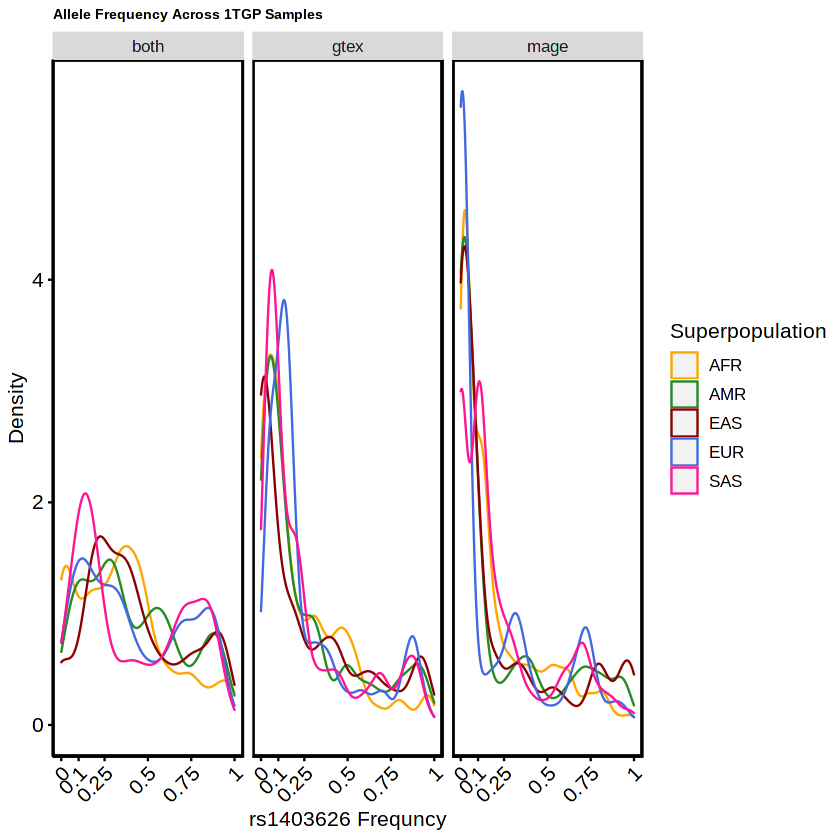

In [95]:
library(ggplot2)
library(ggpubr)

p2 <- ggplot(data=merged[which(merged$set == "TGP"),], aes(x = frequency, color=superpopulation)) +
  #geom_violin() + 
  geom_density() +
  theme(text = element_text(size=12),axis.text=element_text(size=12),
        plot.title =   element_text(size = 8,  face = "bold"),
        axis.title = element_text(),
        axis.text.x=element_text(color="black", angle = 45, vjust = 1, hjust = 1) ,
        axis.text.y=element_text(color="black", size = 12) ,
        panel.background = element_blank(),axis.line = element_line(colour = "black"),
        axis.ticks = element_line(color = "black"),panel.border = element_rect(colour = "black", fill=NA, size=1))+
 scale_x_continuous(breaks = c(0, 0.1, 0.25, 0.5, 0.75, 1),  
                     labels = c("0", "0.1", "0.25", "0.5", "0.75", "1"))  +
  xlab("rs1403626 Frequncy")+
  ylab("Density")+
  ggtitle("")+
facet_wrap(~present_in)+
scale_color_manual(values=c(AFR="orange", EUR="royalblue", EAS="darkred",AMR="forestgreen",SAS="deeppink"))+
 scale_x_continuous(breaks = c(0, 0.1, 0.25, 0.5, 0.75, 1),  
                     labels = c("0", "0.1", "0.25", "0.5", "0.75", "1")) +
ggtitle("Allele Frequency Across 1TGP Samples")

ggpar(p2, legend.title= "Superpopulation")

In [96]:
ggsave("/grid/chambwe/home/founta/code_athon/results/1TGP_density_super_rs1403626.jpeg", 
       width = 24, height = 12, device='jpeg', dpi=700,units = c("cm"))

Generate frequency plot for HGDP populations

Warning message:
“Removed 46 rows containing non-finite values (stat_density).”


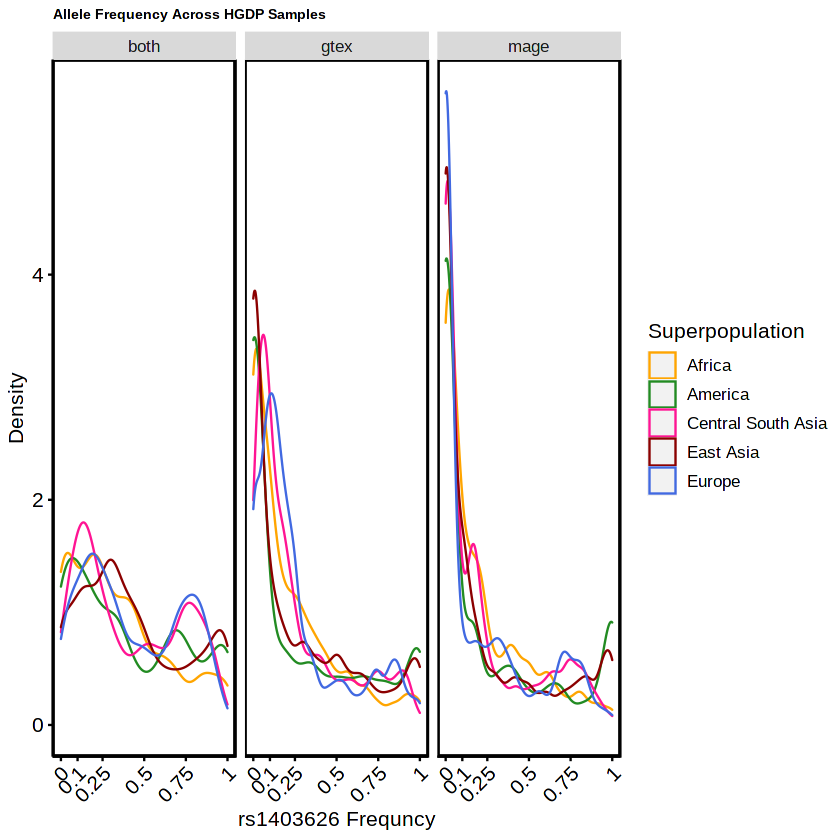

In [91]:
hgdp <- merged[which(merged$set == "HGDP"),]
hgdp <- hgdp[-which(hgdp$superpopulation %in% c("Oceania ", "Middle East ")),]

p4 <- ggplot(data=hgdp, aes(x = frequency, color=superpopulation)) +
  #geom_violin() + 
  geom_density() +
 scale_x_continuous(breaks = c(0, 0.1, 0.25, 0.5, 0.75, 1),  
                     labels = c("0", "0.1", "0.25", "0.5", "0.75", "1"))  +
  theme(text = element_text(size=12),axis.text=element_text(size=12),
        plot.title =   element_text(size = 8,  face = "bold"),
        axis.title = element_text(),
        axis.text.x=element_text(color="black", angle = 45, vjust = 1, hjust = 1) ,
        axis.text.y=element_text(color="black", size = 12) ,
        panel.background = element_blank(),axis.line = element_line(colour = "black"),
        axis.ticks = element_line(color = "black"),panel.border = element_rect(colour = "black", fill=NA, size=1))+
  xlab("rs1403626 Frequncy")+
  ylab("Density")+
  ggtitle("")+
facet_wrap(~present_in)+
scale_color_manual(values=c("Africa "="orange", "Europe "="royalblue", "East Asia "="darkred","America "="forestgreen","Central South Asia "="deeppink"))+
ggtitle("Allele Frequency Across HGDP Samples")

ggpar(p4, legend.title= "Superpopulation")

In [92]:
ggsave("/grid/chambwe/home/founta/code_athon/results/HGDP_density_super_rs1403626.jpeg", 
       width = 24, height = 12, device='jpeg', dpi=700,units = c("cm"))

Warning message:
“Removed 46 rows containing non-finite values (stat_density).”
